In [ ]:
# import libraries
!pip install "flaml[automl]"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from flaml import AutoML
from sklearn.linear_model import LinearRegression
from scipy import stats

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.7/349.7 kB 15.6 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.2.0
    Uninstalling xgboost-3.2.0:
      Successfully uninstalled xgboost-3.2.0


In [ ]:
# data loading
df = pd.read_csv('EIL-MJ1-015.csv', header=0)
df = df.iloc[1:,:] # Drop the Units Row (1st row)
df = df.iloc[:, 5:] # Drops the First 5 columns (summary)
df = df.dropna(axis=1, how='all') # Drops empty columns

# Rearrange all columns into one block.
max_size=df.shape[1] # Number of total columns
block_size=5 # Assign each block as 5 columns
base_cols = ["Cycle", "Time", "Capacity", "Temperature", "Voltage"] # Name all columns
blocks = []

for i in range(0, max_size,block_size): # For loop for all columns with interval at each block
  block = df.iloc[:, i:i+block_size].copy() #  Reads which columns to copy
  blocks.append(block) # Cleans everything to the same column lines
  if block.shape[1] < block_size:  # Checks whether block has less than 5 columns
        continue
  block.columns = base_cols
df_clean_raw = pd.concat(blocks, ignore_index=True) # Combines everything to the same column
df_clean_raw = df_clean_raw.iloc[:,:5] # Drops everything but the first 5 columns
df_clean_raw[[df_clean_raw.columns[0], df_clean_raw.columns[1]]] = df_clean_raw[[df_clean_raw.columns[1], df_clean_raw.columns[0]]] # Swap Cycle and Time Columns ; Names were already Swapped
df_clean_raw[[df_clean_raw.columns[2], df_clean_raw.columns[3]]] = df_clean_raw[[df_clean_raw.columns[3], df_clean_raw.columns[2]]] # Swap Temperature and Capacity Columns ; Names were already Swapped
df_clean_raw = df_clean_raw.iloc[:,:3] # Only need Cycle, Time, and Capacity

# Convert relevant columns to numeric before dropping NaNs and performing calculations
df_clean_raw['Cycle'] = pd.to_numeric(df_clean_raw['Cycle'], errors='coerce')
df_clean_raw['Time'] = pd.to_numeric(df_clean_raw['Time'], errors='coerce')
df_clean_raw['Capacity'] = pd.to_numeric(df_clean_raw['Capacity'], errors='coerce')
df_clean_raw = df_clean_raw.dropna(axis=0, how='any') # Drops every row with at least one empty value

# Separate Charge and Discharge Cycles
df_no_charge = []
df_charge = []

for cycle, group in df_clean_raw.groupby("Cycle"): # Group everything by "Cycle"
  group = group.sort_values("Time").reset_index(drop=True) # Arranges everything in cycle by time
  cap = group["Capacity"].values # Look at Capacities
  start = None # Starts the counter (Not known yet).
  for i in range(len(cap)): # Set a for loop for every cycle. We are counting the rows that go up then go back to 0.
    if cap[i] > 0: # Checks if capacity at position is at 0
      start = i # Starts the counter.
      break
  end = None # Ends the counter (Not known yet).
  if start is not None: # Runs if loop if start has been found
      for i in range(start + 1, len(cap)): # Starts to look for end once capacity is lower than 0.000001 (basically zero)
        if cap[i] <= 0.0000001:
          end = i
          break
  if start is not None and end is not None:   # If both start and end have been found, we put all the start to end values in charge and then end+1 onwards in discharge
    charge_part = group.iloc[start:end+1]
    discharge_part = group.iloc[end+1:]
    df_charge.append(charge_part)
    df_no_charge.append(discharge_part)
  else:
    df_no_charge.append(group)

df_charge= pd.concat(df_charge, ignore_index=True)
df_no_charge = pd.concat(df_no_charge, ignore_index=True) # Combined data
df_charge = df_charge[df_charge["Capacity"]>0] # Remove 0 values to simplify time with no capacity reading
df_no_charge = df_no_charge[df_no_charge["Capacity"]>0] # Remove 0 values to simplify time with no capacity reading

# Finding the Max (Charge/Discharge Capacity) and the Time Cycle (Charge/Discharge Time)
df_dis_sum=df_no_charge.groupby("Cycle").agg(Discharge_capacity=("Capacity","max"),Discharge_time=("Time", lambda x: x.max()-x.min())).reset_index()
df_cha_sum=df_charge.groupby("Cycle").agg(Charge_capacity=("Capacity","max"),Charge_time=("Time", lambda x: x.max()-x.min())).reset_index()

# Merging and Adding Coloumbic Efficiency and Time Efficiency
df_clean = pd.merge(df_dis_sum, df_cha_sum, on="Cycle")
df_clean["Coulombic_efficiency"] = (df_clean["Discharge_capacity"] / df_clean["Charge_capacity"])
df_clean["Time_efficiency"] = (df_clean["Discharge_time"] / df_clean["Charge_time"])
df_clean.to_csv("df_clean.csv", index=False) # To see CSV File in Excel

df_clean

/tmp/ipykernel_1827/3244210250.py:2: DtypeWarning: Columns (0,1,2,3,5,6,7,8,9,11,12,13,14,15,17,18,19,20,21,23,24,25,26,27,29,30,31,32,33) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('EIL-MJ1-015.csv', header=0)


,Cycle,Discharge_capacity,Discharge_time,Charge_capacity,Charge_time,Coulombic_efficiency,Time_efficiency
0,1.0,3.371632,0.842903,3.474988,2.783056,0.970257,0.302870
1,2.0,3.367443,0.841856,3.379767,2.703653,0.996354,0.311377
2,3.0,3.357865,0.839458,3.373153,2.693045,0.995468,0.311714
3,4.0,3.348510,0.837122,3.361795,2.684589,0.996048,0.311825
4,5.0,3.343454,0.835858,3.353153,2.669995,0.997108,0.313056
...,...,...,...,...,...,...,...
395,396.0,2.876391,0.735303,2.878227,2.485778,0.999362,0.295804
396,397.0,2.876958,0.735353,2.876518,2.484117,1.000153,0.296022
397,398.0,2.876302,0.735369,2.877147,2.483692,0.999706,0.296079
398,399.0,2.875836,0.734961,2.876007,2.472886,0.999941,0.297208


In [ ]:
x_clean = df_clean[['Cycle', 'Coulombic_efficiency', 'Time_efficiency']]
y_clean = df_clean['Discharge_capacity']

In [ ]:
# train/test split
x_train, x_test, y_train, y_test = train_test_split(x_clean, y_clean, test_size=0.3, random_state=42)

In [ ]:
# model selection
model_lr = LinearRegression()
model_aml = AutoML(seed=42,
               time_budget=60, # in seconds
               metric="mae",
               task="regression",
               )

In [ ]:
# training/testing
model_lr.fit(x_train, y_train)
y_predict_lr = model_lr.predict(x_test)

model_aml.fit(x_train, y_train)
y_predict_aml = model_aml.predict(x_test)

[flaml.automl.logger: 05-04 03:27:06] {2375} INFO - task = regression
[flaml.automl.logger: 05-04 03:27:06] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 05-04 03:27:06] {2489} INFO - Minimizing error metric: mae
[flaml.automl.logger: 05-04 03:27:06] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd']
[flaml.automl.logger: 05-04 03:27:06] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 05-04 03:27:07] {3046} INFO - Estimated sufficient time budget=3486s. Estimated necessary time budget=25s.
[flaml.automl.logger: 05-04 03:27:07] {3097} INFO -  at 0.4s,	estimator lgbm's best error=6.4392e-02,	best estimator lgbm's best error=6.4392e-02
[flaml.automl.logger: 05-04 03:27:07] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 05-04 03:27:07] {3097} INFO -  at 0.6s,	estimator lgbm's best error=6.4392e-02,	best estimator lgbm's best error=6.4392e-02
[flaml.automl.logger: 05-04 03

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 05-04 03:27:07] {3097} INFO -  at 1.0s,	estimator sgd's best error=9.3756e-02,	best estimator lgbm's best error=3.4914e-02
[flaml.automl.logger: 05-04 03:27:07] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 05-04 03:27:09] {3097} INFO -  at 2.5s,	estimator lgbm's best error=1.2795e-02,	best estimator lgbm's best error=1.2795e-02
[flaml.automl.logger: 05-04 03:27:09] {2911} INFO - iteration 5, current learner sgd
[flaml.automl.logger: 05-04 03:27:09] {3097} INFO -  at 2.8s,	estimator sgd's best error=9.3756e-02,	best estimator lgbm's best error=1.2795e-02
[flaml.automl.logger: 05-04 03:27:09] {2911} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 05-04 03:27:10] {3097} INFO -  at 3.5s,	estimator xgboost's best error=6.4042e-02,	best estimator lgbm's best error=1.2795e-02
[flaml.automl.logger: 05-04 03:27:10] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 05-04 03:27:10] {3097} INFO -  at 3.6s,	estimat

In [ ]:
# performance analysis - linear regression
mean_absolute_error(y_test,y_predict_lr)

0.03722266888318723

In [ ]:
# performance analysis - autoML
mean_absolute_error(y_test,y_predict_aml)

0.002141759925671201

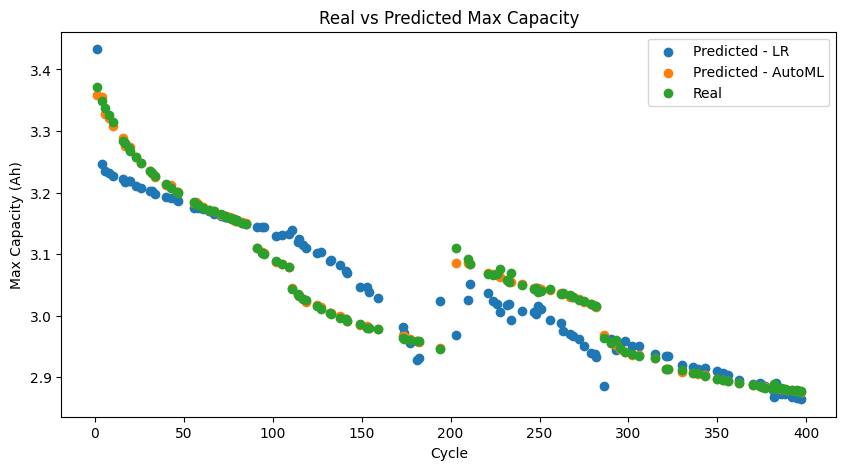

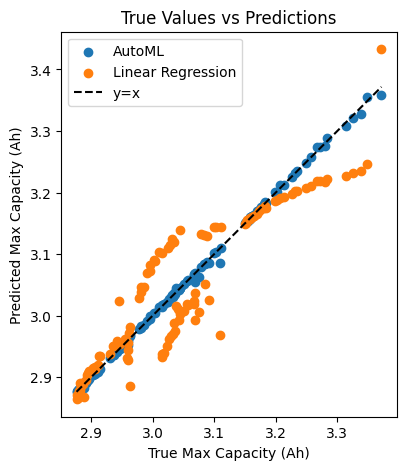

In [ ]:
# visualization of performance

# linear regression plot
plt.figure(figsize=(10, 5))
plt.scatter(x_test['Cycle'], y_predict_lr, label='Predicted - LR')
plt.scatter(x_test['Cycle'], y_predict_aml, label='Predicted - AutoML')
plt.scatter(x_test['Cycle'], y_test, label='Real')
plt.legend()
plt.xlabel('Cycle')
plt.ylabel('Max Capacity (Ah)')
plt.title('Real vs Predicted Max Capacity')
plt.show()

# autoML plot
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_predict_aml, label='AutoML')
plt.scatter(y_test, y_predict_lr, label='Linear Regression')
plt.xlabel('True Max Capacity (Ah)')
plt.ylabel('Predicted Max Capacity (Ah)')
plt.title('True Values vs Predictions')
plt.gca().set_aspect('equal', adjustable='box') # Keep aspect ratio for y=x line
# Adjust limits for the y=x line
min_val = min(y_test.min(), y_predict_aml.min())
max_val = max(y_test.max(), y_predict_aml.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='y=x')
plt.legend()
plt.show()

In [ ]:
# hypothesis testing
abs_errors_aml = abs(y_test - y_predict_aml)
abs_errors_lr = abs(y_test - y_predict_lr)
t_statistics, p_value = stats.ttest_rel(abs_errors_aml, abs_errors_lr, alternative='less')
print(f"t-statistic = {t_statistics:.4f}")
print(f"p-value = {p_value:.6f}")

t-statistic = -12.4227
p-value = 0.000000
